<a href="https://colab.research.google.com/github/Ranjitkumarmuduli/tomato-disease-detection/blob/main/03_evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 3 – Evaluation and Explainability
Compare the 4 trained models, analyse the best one in detail (per-class results, confusion matrix,
mistakes), show where it looks on the leaf (Grad-CAM), choose a confidence threshold for the app,
and export the final model for the application.

## 1. Install libraries

In [1]:
!pip -q install timm kagglehub

## 2. Import libraries

In [2]:
import os, time, json, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import timm, kagglehub
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import classification_report, confusion_matrix

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU – switch to T4 GPU!")

Device: Tesla T4


## 3. Load the test set
Only the **test** split is used here. These images were never used in training or model selection.
The preprocessing must be exactly the same as in Step 2 (resize 224 + ImageNet normalisation).

In [3]:
from google.colab import drive
drive.mount('/content/drive')

PROJ = "/content/drive/MyDrive/tomato_project"
base = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
ROOT = f"{base}/plantvillage dataset/color"

CLASSES = pd.read_csv(f"{PROJ}/splits/classes.csv", header=None)[0].tolist()
NUM_CLASSES = len(CLASSES)
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])

class TomatoLeafDataset(Dataset):
    def __init__(self, frame, transform):
        self.data, self.transform = frame, transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, i):
        row = self.data.iloc[i]
        return self.transform(Image.open(f"{ROOT}/{row.relpath}").convert("RGB")), int(row.label)

test_df = pd.read_csv(f"{PROJ}/splits/test.csv")
test_dl = DataLoader(TomatoLeafDataset(test_df, eval_tf), batch_size=64, num_workers=2)  # no shuffle: order = test_df order
print("Test images:", len(test_df))

Mounted at /content/drive
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Test images: 2722


## 4. Load trained models from Drive
The Baseline CNN class must be **identical** to Step 2, otherwise its saved weights won't load.
Pretrained models are rebuilt empty (`pretrained=False`) and filled with our trained weights.

In [4]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
                                 nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def load_model(name):
    if name == "baseline_cnn":
        model = BaselineCNN(NUM_CLASSES)
    else:
        model = timm.create_model(name, pretrained=False, num_classes=NUM_CLASSES)
    model.load_state_dict(torch.load(f"{PROJ}/weights/{name}.pt", map_location="cpu"))
    return model.eval()

print("Saved weights:", os.listdir(f"{PROJ}/weights"))

Saved weights: ['efficientnet_b0.pt', 'mobilenetv3_large_100.pt', 'resnet50.pt', 'baseline_cnn.pt']


## 5. Model comparison (main results table – Chapter 5)
Adds **inference time** (milliseconds per image) to the Step 2 results:
- **GPU ms:** speed on the Colab T4
- **CPU ms:** speed on a normal computer. The free Hugging Face app runs on CPU, so this number matters for deployment.

In [5]:
@torch.no_grad()
def ms_per_image(model, device, runs=30):
    model = model.to(device)
    x = torch.randn(1, 3, 224, 224, device=device)    # one dummy image
    for _ in range(5): model(x)                       # warm-up
    if device == "cuda": torch.cuda.synchronize()
    start = time.time()
    for _ in range(runs): model(x)
    if device == "cuda": torch.cuda.synchronize()
    return (time.time() - start) / runs * 1000

summary = pd.read_csv(f"{PROJ}/results/summary.csv")
speeds = []
for name in summary.model:
    m = load_model(name)
    speeds.append(dict(model=name, gpu_ms=round(ms_per_image(m, "cuda"), 1),
                       cpu_ms=round(ms_per_image(m, "cpu", runs=10), 1)))
    print("timed", name)

comparison = summary.merge(pd.DataFrame(speeds), on="model").sort_values("macro_f1", ascending=False)
comparison.to_csv(f"{PROJ}/results/comparison.csv", index=False)
comparison

timed efficientnet_b0
timed mobilenetv3_large_100
timed resnet50
timed baseline_cnn


,model,test_accuracy,macro_f1,params_million,size_MB,train_minutes,gpu_ms,cpu_ms
0,efficientnet_b0,0.9974,0.9966,4.02,16.4,14.2,8.1,44.9
1,mobilenetv3_large_100,0.9941,0.9934,4.21,17.1,12.9,6.4,25.2
2,resnet50,0.9923,0.9903,23.53,94.4,14.4,8.4,133.0
3,baseline_cnn,0.9467,0.9337,0.39,1.6,12.1,2.0,40.6


## 6. Accuracy vs model size
Shows the trade-off: does a bigger model really give better results?
Points at the top-left (accurate and small) are best for a mobile or web app.

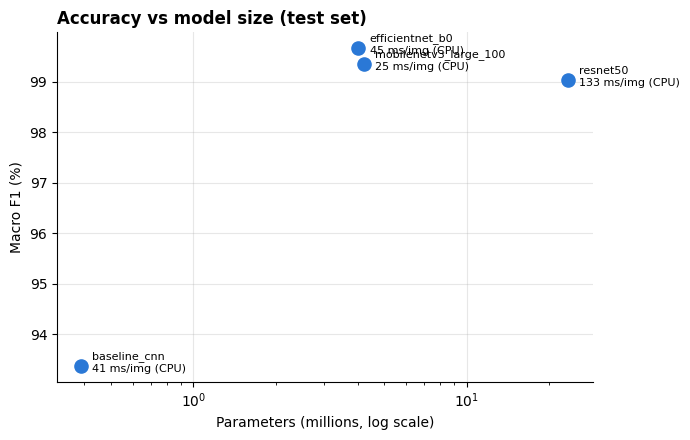

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(comparison.params_million, comparison.macro_f1 * 100, s=90, color="#2a78d6", zorder=3)
for _, r in comparison.iterrows():
    ax.annotate(f"{r.model}\n{r.cpu_ms:.0f} ms/img (CPU)", (r.params_million, r.macro_f1 * 100),
                textcoords="offset points", xytext=(8, -4), fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Parameters (millions, log scale)"); ax.set_ylabel("Macro F1 (%)")
ax.set_title("Accuracy vs model size (test set)", loc="left", fontweight="bold")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/accuracy_vs_size.png", dpi=300); plt.show()

## 7. Select the best model and predict the test set
The best model is the one with the **highest macro F1**. For every test image we keep:
the true class, the predicted class, and the **confidence** (the probability of the predicted class).

In [7]:
BEST = comparison.iloc[0].model          # highest macro F1
assert BEST != "baseline_cnn", "Best should be a pretrained model"
model = load_model(BEST).to(DEVICE)

all_probs, y_true = [], []
with torch.no_grad():
    for x, y in test_dl:
        all_probs.append(torch.softmax(model(x.to(DEVICE)), dim=1).cpu())
        y_true += y.tolist()
probs  = torch.cat(all_probs).numpy()
y_true = np.array(y_true)
y_pred = probs.argmax(1)                 # predicted class
conf   = probs.max(1)                    # confidence of that prediction

print(f"Best model: {BEST} | correct {np.sum(y_pred == y_true)} / {len(y_true)} | "
      f"wrong {np.sum(y_pred != y_true)}")

Best model: efficientnet_b0 | correct 2715 / 2722 | wrong 7


## 8. Per-class results
- **Precision:** of the images predicted as this disease, how many really were (few false alarms)
- **Recall:** of the images that really have this disease, how many were found (few missed cases)
- **F1:** a balance of the two
- **Support:** number of test images in the class

In [8]:
report = pd.DataFrame(classification_report(y_true, y_pred, target_names=CLASSES,
                                            output_dict=True, digits=4)).T.round(4)
report["support"] = report["support"].astype(int)
report.to_csv(f"{PROJ}/results/classification_report_{BEST}.csv")
report

,precision,recall,f1-score,support
Bacterial_spot,1.0000,0.9969,0.9984,319
Early_blight,0.9933,0.9867,0.9900,150
Late_blight,1.0000,0.9965,0.9982,285
Leaf_Mold,1.0000,1.0000,1.0000,143
Septoria_leaf_spot,1.0000,1.0000,1.0000,266
Spider_mites Two-spotted_spider_mite,0.9960,0.9960,0.9960,251
Target_Spot,0.9812,0.9905,0.9858,211
Tomato_Yellow_Leaf_Curl_Virus,1.0000,1.0000,1.0000,803
Tomato_mosaic_virus,1.0000,1.0000,1.0000,56
healthy,0.9958,1.0000,0.9979,238


## 9. Confusion matrix
Rows = true class, columns = predicted class. The diagonal holds the correct predictions.
Any number **off** the diagonal is a mistake and shows which diseases get confused with each other.
Colour = the share of each true class (row).

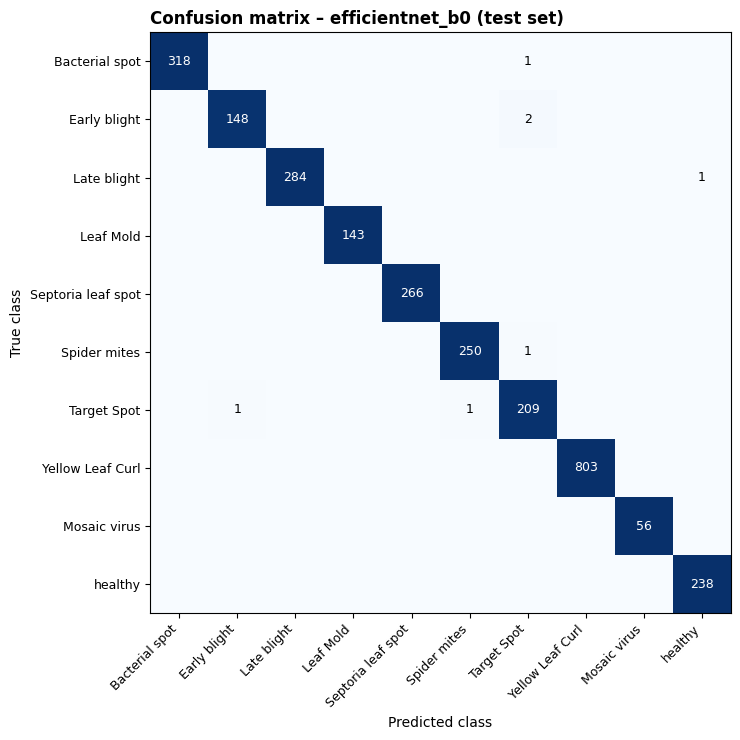

In [9]:
cm = confusion_matrix(y_true, y_pred)
cm_share = cm / cm.sum(axis=1, keepdims=True)
short = [c.replace("Spider_mites Two-spotted_spider_mite", "Spider mites")
          .replace("Tomato_Yellow_Leaf_Curl_Virus", "Yellow Leaf Curl")
          .replace("Tomato_mosaic_virus", "Mosaic virus").replace("_", " ") for c in CLASSES]

fig, ax = plt.subplots(figsize=(8.5, 7.5))
ax.imshow(cm_share, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm_share[i, j] > 0.5 else "black")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(short, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(short, fontsize=9)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title(f"Confusion matrix – {BEST} (test set)", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/confusion_matrix_{BEST}.png", dpi=300); plt.show()

## 10. Misclassified images (error analysis)
Looking at the wrong predictions helps explain them in the thesis
(similar-looking symptoms, unclear photos, possible labelling errors in the dataset).

7 misclassified test images


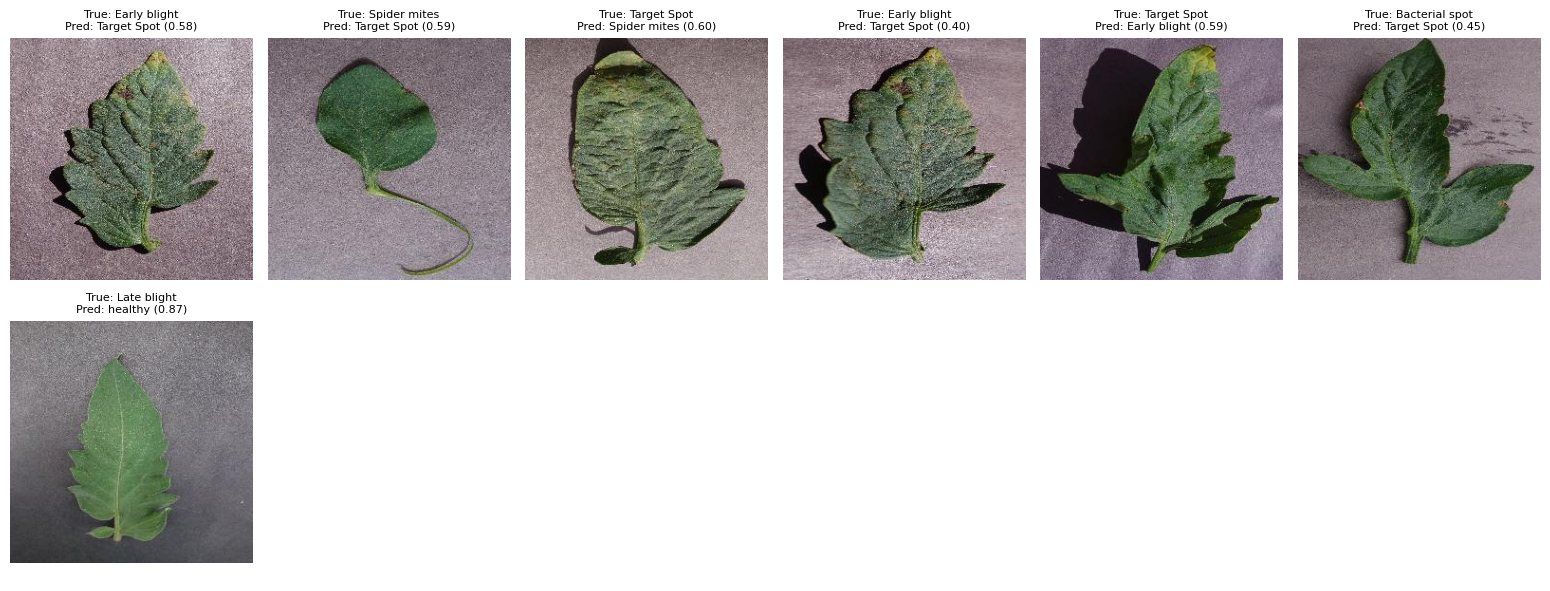

In [10]:
wrong = np.where(y_pred != y_true)[0]
print(len(wrong), "misclassified test images")
show = wrong[:12]
if len(show):
    cols = 6; rows = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.6, rows * 3), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, i in zip(axes.flat, show):
        ax.imshow(Image.open(f"{ROOT}/{test_df.relpath.iloc[i]}"))
        ax.set_title(f"True: {short[y_true[i]]}\nPred: {short[y_pred[i]]} ({conf[i]:.2f})", fontsize=8)
    plt.tight_layout(); plt.savefig(f"{PROJ}/figures/misclassified_{BEST}.png", dpi=200); plt.show()

## 11. Grad-CAM (explainable AI)
Grad-CAM produces a **heatmap of the pixels that most influenced the prediction**.
If the red areas sit on the disease spots (and not on the background), the model learned real
symptoms. This answers the examiner question: *"How do we know the model isn't cheating?"*

How it works: take the last convolutional feature maps → weight each map by how much it pushes
the predicted class up (its gradient) → add them up → keep the positive part → resize to the image.

In [11]:
def grad_cam(model, img_tensor):
    model.eval()
    x = img_tensor.unsqueeze(0).to(DEVICE)
    feats = model.forward_features(x)          # last feature maps (1, C, h, w), before pooling
    feats.retain_grad()                        # keep their gradients
    logits = model.forward_head(feats)         # pooling + classifier
    cls = logits.argmax(1).item()
    model.zero_grad()
    logits[0, cls].backward()                  # gradient of the predicted class score
    weights = feats.grad.mean(dim=(2, 3), keepdim=True)          # importance of each feature map
    cam = F.relu((weights * feats).sum(dim=1, keepdim=True))     # weighted sum, positive only
    cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)    # scale to 0-1
    prob = torch.softmax(logits, 1)[0, cls].item()
    return cam.detach().cpu().numpy(), cls, prob

def denormalise(t):
    return (t.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

## 12. Grad-CAM for each class (thesis figure)
Top row: original test image. Bottom row: heatmap overlay (red = most important).

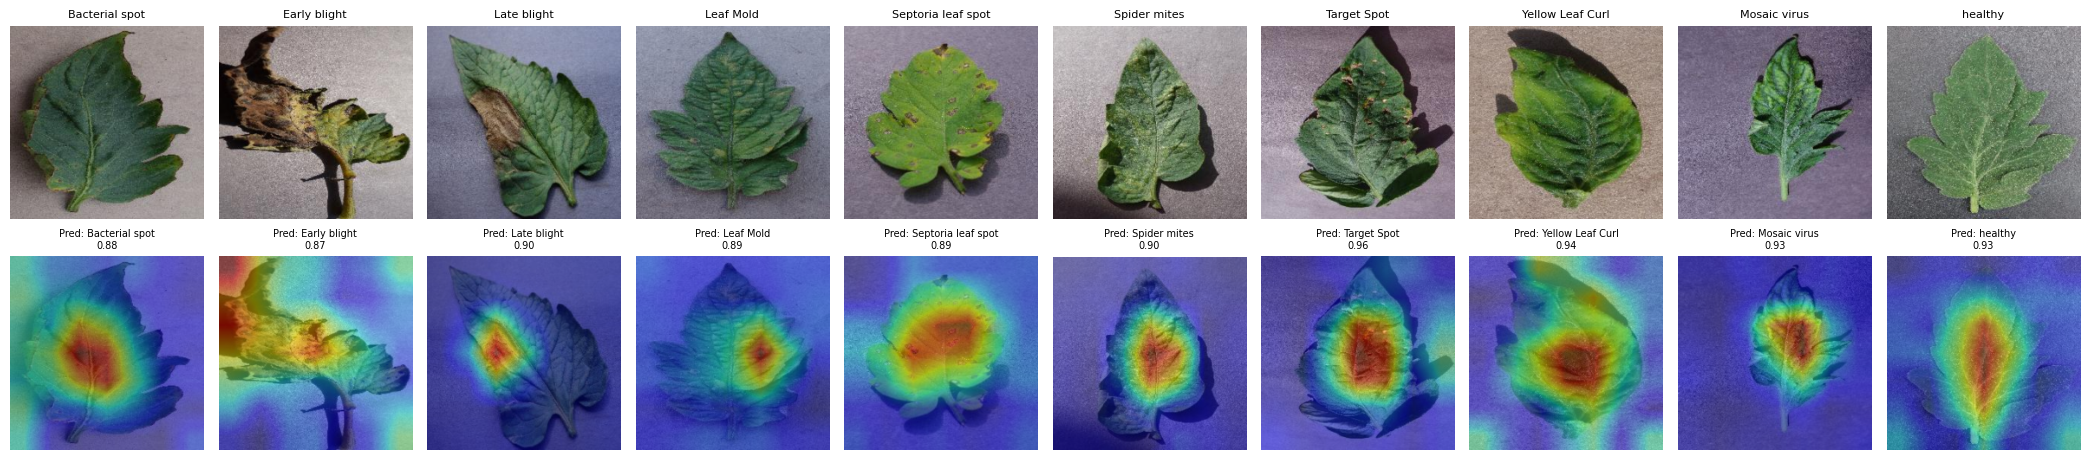

In [12]:
examples = test_df.groupby("label").head(1).sort_values("label")     # first test image of each class
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(2.1 * NUM_CLASSES, 4.8))
for k, (_, row) in enumerate(examples.iterrows()):
    t = eval_tf(Image.open(f"{ROOT}/{row.relpath}").convert("RGB"))
    cam, cls, prob = grad_cam(model, t)
    img = denormalise(t)
    axes[0, k].imshow(img); axes[0, k].set_title(short[row.label], fontsize=8)
    axes[1, k].imshow(img); axes[1, k].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, k].set_title(f"Pred: {short[cls]}\n{prob:.2f}", fontsize=7)
    for ax in axes[:, k]: ax.axis("off")
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/gradcam_{BEST}.png", dpi=300); plt.show()

## 13. Choose a confidence threshold for the app
If the model is unsure, the app should say *"Not sure – consult an expert"* instead of giving
possibly wrong treatment advice. This table shows, for each threshold:
- how many test images the app would still answer
- the accuracy on the answered images
- how many of the wrong predictions would be caught (sent to "not sure")

Note: label smoothing makes the model's confidence values lower than 1.0, so typical correct
predictions sit around 0.85–0.95.

In [13]:
errors = (y_pred != y_true)
rows = []
for t in [0.4, 0.5, 0.6, 0.7, 0.8]:
    answered = conf >= t
    rows.append(dict(threshold=t, answered=f"{answered.mean():.1%}",
                     accuracy_on_answered=f"{(y_pred[answered] == y_true[answered]).mean():.2%}",
                     errors_caught=f"{(errors & ~answered).sum()} / {errors.sum()}"))
pd.DataFrame(rows)

,threshold,answered,accuracy_on_answered,errors_caught
0,0.4,99.9%,99.78%,1 / 7
1,0.5,99.6%,99.82%,2 / 7
2,0.6,99.1%,99.93%,5 / 7
3,0.7,98.4%,99.96%,6 / 7
4,0.8,95.5%,99.96%,6 / 7


## 14. Export the model for the application
Saves everything the app needs into `tomato_project/app_model/`:
- `model.pt`: trained weights
- `config.json`: model name, class names, preprocessing settings and the confidence threshold

**Set `THRESHOLD`** to the value you choose from Cell 13 (a good choice answers about 98–99% of images and catches most errors).

In [14]:
THRESHOLD = 0.6        # <- update after looking at Cell 13

APP = f"{PROJ}/app_model"
os.makedirs(APP, exist_ok=True)
shutil.copy(f"{PROJ}/weights/{BEST}.pt", f"{APP}/model.pt")
config = {"model_name": BEST, "classes": CLASSES, "img_size": 224,
          "mean": MEAN, "std": STD, "confidence_threshold": THRESHOLD}
json.dump(config, open(f"{APP}/config.json", "w"), indent=2)
print("Exported:", os.listdir(APP))
print(json.dumps(config, indent=2))

Exported: ['model.pt', 'config.json']
{
  "model_name": "efficientnet_b0",
  "classes": [
    "Bacterial_spot",
    "Early_blight",
    "Late_blight",
    "Leaf_Mold",
    "Septoria_leaf_spot",
    "Spider_mites Two-spotted_spider_mite",
    "Target_Spot",
    "Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato_mosaic_virus",
    "healthy"
  ],
  "img_size": 224,
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "confidence_threshold": 0.6
}
